In [1]:
!pip install cadquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 MB 26.8 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.0/146.0 MB 28.4 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.2/93.2 MB 32.8 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.3/568.3 kB 24.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.0/852.0 kB 38.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 33.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [cadquery]


In [3]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:11
🔁 Restarting kernel...


In [1]:
!conda install -c conda-forge pythonocc-core -y


Retrieving notices: - \ | done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: - \ | / - \ | / - \ | done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - pythonocc-core


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _python_abi3_support-1.0   |       hd8ed1ab_3           8 KB  conda-forge
    aiohappyeyeballs-2.7.1     |     pyhd8ed1ab_0          24 KB  conda-forge
    aiohttp-3.14.5             |  py313h2af15c8_1         1.2 MB  conda-forge
    aiosignal-1.4.0            |     pyhd8ed1ab_0          13 KB  conda-forge
    alsa-lib-1.2.16.1          |       h7cc23a3_1         581 KB  conda-forge
    annotated-types-0.8.0      |     pyhd8ed1ab_0          19 KB  conda-forge
    anyio-4.16.0               |     pyh5ded981_1         182 KB  conda-forge
    aom-3.14.1                 | pl5321h57e6904_2     

In [3]:
from OCC.Core.BRepPrimAPI import BRepPrimAPI_MakeBox

box = BRepPrimAPI_MakeBox(10, 20, 30).Shape()

print("Open CASCADE working!")
box

Open CASCADE working!


<class 'TopoDS_Solid'>

In [4]:
from OCC.Core.TopExp import TopExp_Explorer
from OCC.Core.TopAbs import (
    TopAbs_FACE,
    TopAbs_EDGE,
    TopAbs_VERTEX
)

def count_elements(shape, element_type):
    explorer = TopExp_Explorer(shape, element_type)

    count = 0

    while explorer.More():
        count += 1
        explorer.Next()

    return count


print("Faces:", count_elements(box, TopAbs_FACE))
print("Edges:", count_elements(box, TopAbs_EDGE))
print("Vertices:", count_elements(box, TopAbs_VERTEX))

Faces: 6
Edges: 24
Vertices: 48


In [5]:
from OCC.Core.BRepPrimAPI import (
    BRepPrimAPI_MakeBox,
    BRepPrimAPI_MakeCylinder
)

from OCC.Core.BRepAlgoAPI import BRepAlgoAPI_Cut
from OCC.Core.gp import gp_Ax2, gp_Pnt, gp_Dir

# Create a rectangular block: 40 x 30 x 10 mm
block = BRepPrimAPI_MakeBox(40, 30, 10).Shape()

# Create a cylindrical tool
axis = gp_Ax2(
    gp_Pnt(20, 15, 0),
    gp_Dir(0, 0, 1)
)

cylinder = BRepPrimAPI_MakeCylinder(
    axis, 5, 10
).Shape()

# Subtract cylinder from block
part = BRepAlgoAPI_Cut(block, cylinder).Shape()

print(type(part))

<class 'OCC.Core.TopoDS.TopoDS_Compound'>


In [7]:
from OCC.Core.STEPControl import (
    STEPControl_Writer,
    STEPControl_AsIs
)

from OCC.Core.IFSelect import IFSelect_RetDone

writer = STEPControl_Writer()

writer.Transfer(part, STEPControl_AsIs)

status = writer.Write("test_part.step")

print("STEP exported:", status == IFSelect_RetDone)

STEP exported: True


In [8]:
from OCC.Core.STEPControl import STEPControl_Reader

reader = STEPControl_Reader()

status = reader.ReadFile("test_part.step")

if status == IFSelect_RetDone:
    reader.TransferRoots()
    shape = reader.OneShape()

print(type(shape))

<class 'OCC.Core.TopoDS.TopoDS_Solid'>


In [10]:
from OCC.Core.TopExp import TopExp_Explorer

from OCC.Core.TopAbs import (
    TopAbs_FACE,
    TopAbs_EDGE,
    TopAbs_VERTEX
)

from OCC.Core.TopoDS import topods

In [13]:
face_explorer = TopExp_Explorer(
    shape,
    TopAbs_FACE
)

In [14]:
while face_explorer.More():

    current_face = face_explorer.Current()

    print(current_face)

    face_explorer.Next()

<class 'TopoDS_Face'>
<class 'TopoDS_Face'>
<class 'TopoDS_Face'>
<class 'TopoDS_Face'>
<class 'TopoDS_Face'>
<class 'TopoDS_Face'>
<class 'TopoDS_Face'>


In [16]:
faces = []

face_explorer = TopExp_Explorer(
    shape,
    TopAbs_FACE
)

while face_explorer.More():

    current_face = topods.Face(
        face_explorer.Current()
    )

    faces.append(current_face)

    face_explorer.Next()

In [17]:
print("Total faces:", len(faces))

Total faces: 7


In [18]:
edges = []

edge_explorer = TopExp_Explorer(
    shape,
    TopAbs_EDGE
)

while edge_explorer.More():

    current_edge = topods.Edge(
        edge_explorer.Current()
    )

    edges.append(current_edge)

    edge_explorer.Next()

print("Total edges:", len(edges))

Total edges: 30


In [19]:
vertices = []

vertex_explorer = TopExp_Explorer(
    shape,
    TopAbs_VERTEX
)

while vertex_explorer.More():

    current_vertex = topods.Vertex(
        vertex_explorer.Current()
    )

    vertices.append(current_vertex)

    vertex_explorer.Next()

print("Total vertices:", len(vertices))

Total vertices: 60


In [20]:
def extract_topology(shape, element_type, converter):

    elements = []

    explorer = TopExp_Explorer(
        shape,
        element_type
    )

    while explorer.More():

        element = converter(
            explorer.Current()
        )

        elements.append(element)

        explorer.Next()

    return elements

In [21]:
faces = extract_topology(
    shape,
    TopAbs_FACE,
    topods.Face
)

edges = extract_topology(
    shape,
    TopAbs_EDGE,
    topods.Edge
)

vertices = extract_topology(
    shape,
    TopAbs_VERTEX,
    topods.Vertex
)

In [22]:
print("Faces:", len(faces))
print("Edges:", len(edges))
print("Vertices:", len(vertices))

Faces: 7
Edges: 30
Vertices: 60


In [23]:

# ==========================================
# PHASE 3: GEOMETRIC FEATURE EXTRACTION
# ==========================================

# 1. Import the required modules

from OCC.Core.BRepAdaptor import BRepAdaptor_Surface

from OCC.Core.GeomAbs import (
    GeomAbs_Plane,
    GeomAbs_Cylinder,
    GeomAbs_Cone,
    GeomAbs_Sphere,
    GeomAbs_Torus
)

from OCC.Core.BRepGProp import brepgprop_SurfaceProperties
from OCC.Core.GProp import GProp_GProps


# 2. Create a dictionary for surface classification

surface_names = {
    GeomAbs_Plane: "Plane",
    GeomAbs_Cylinder: "Cylinder",
    GeomAbs_Cone: "Cone",
    GeomAbs_Sphere: "Sphere",
    GeomAbs_Torus: "Torus"
}


# 3. Create an empty list to store extracted features

face_features = []


# 4. Loop through every face

for i, face in enumerate(faces):

    # Create an adaptor to inspect the face's geometry
    surface = BRepAdaptor_Surface(face)

    # Identify the underlying surface type
    surface_type = surface.GetType()

    # Convert the surface identifier into a readable name
    surface_name = surface_names.get(surface_type, "Other")


    # 5. Calculate the surface area

    props = GProp_GProps()

    brepgprop_SurfaceProperties(face, props)

    area = props.Mass()


    # 6. Store the basic properties of the face

    features = {
        "face_id": i,
        "surface_type": surface_name,
        "area": area
    }


    # 7. Extract additional properties if the face is cylindrical

    if surface_type == GeomAbs_Cylinder:

        cylinder = surface.Cylinder()

        radius = cylinder.Radius()

        axis = cylinder.Axis()

        location = axis.Location()

        direction = axis.Direction()

        features["radius"] = radius

        features["axis_location"] = (
            location.X(),
            location.Y(),
            location.Z()
        )

        features["axis_direction"] = (
            direction.X(),
            direction.Y(),
            direction.Z()
        )


    # 8. Add this face's feature dictionary to our list

    face_features.append(features)


# 9. Display the extracted information

for feature in face_features:

    print(feature)


{'face_id': 0, 'surface_type': 'Plane', 'area': 299.99999999999994}
{'face_id': 1, 'surface_type': 'Plane', 'area': 399.99999999999994}
{'face_id': 2, 'surface_type': 'Plane', 'area': 1121.4601836602549}
{'face_id': 3, 'surface_type': 'Plane', 'area': 399.99999999999994}
{'face_id': 4, 'surface_type': 'Plane', 'area': 1121.4601836602549}
{'face_id': 5, 'surface_type': 'Plane', 'area': 299.99999999999994}
{'face_id': 6, 'surface_type': 'Cylinder', 'area': 314.159265359, 'radius': 5.0, 'axis_location': (20.0, 15.0, 0.0), 'axis_direction': (0.0, 0.0, 1.0)}


/tmp/ipykernel_2494/2584557891.py:55: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2584557891.py:55: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2584557891.py:55: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2584557891.py:55: DeprecationWarning: Call to deprecated function brepgprop_Surf

In [24]:

# ==========================================
# PHASE 4: B-REP FACE ADJACENCY
# ==========================================

from OCC.Core.TopExp import TopExp_Explorer
from OCC.Core.TopAbs import TopAbs_EDGE
from OCC.Core.TopoDS import topods


# 1. Extract the edges belonging to each face

face_edges = []

for face_id, face in enumerate(faces):

    current_face_edges = []

    explorer = TopExp_Explorer(face, TopAbs_EDGE)

    while explorer.More():

        edge = topods.Edge(explorer.Current())

        # Avoid storing the same edge twice within this face
        already_present = any(
            edge.IsSame(existing_edge)
            for existing_edge in current_face_edges
        )

        if not already_present:
            current_face_edges.append(edge)

        explorer.Next()

    face_edges.append(current_face_edges)


# 2. Compare every pair of faces

adjacency = []

for i in range(len(faces)):

    for j in range(i + 1, len(faces)):

        shared_edges = []

        for edge_i in face_edges[i]:

            for edge_j in face_edges[j]:

                if edge_i.IsSame(edge_j):
                    shared_edges.append(edge_i)

        # If at least one edge is shared, faces are adjacent
        if len(shared_edges) > 0:

            adjacency.append({
                "face_1": i,
                "face_2": j,
                "shared_edge_count": len(shared_edges)
            })


# 3. Display the adjacency relationships

print("Face adjacency relationships:\n")

for connection in adjacency:
    print(connection)


# 4. Create a simple adjacency list

adjacency_list = {i: [] for i in range(len(faces))}

for connection in adjacency:

    i = connection["face_1"]
    j = connection["face_2"]

    adjacency_list[i].append(j)
    adjacency_list[j].append(i)


print("\nAdjacency list:\n")

for face_id, neighbours in adjacency_list.items():
    print(f"Face {face_id}: {neighbours}")


Face adjacency relationships:

{'face_1': 0, 'face_2': 1, 'shared_edge_count': 1}
{'face_1': 0, 'face_2': 2, 'shared_edge_count': 1}
{'face_1': 0, 'face_2': 3, 'shared_edge_count': 1}
{'face_1': 0, 'face_2': 4, 'shared_edge_count': 1}
{'face_1': 1, 'face_2': 2, 'shared_edge_count': 1}
{'face_1': 1, 'face_2': 4, 'shared_edge_count': 1}
{'face_1': 1, 'face_2': 5, 'shared_edge_count': 1}
{'face_1': 2, 'face_2': 3, 'shared_edge_count': 1}
{'face_1': 2, 'face_2': 5, 'shared_edge_count': 1}
{'face_1': 2, 'face_2': 6, 'shared_edge_count': 1}
{'face_1': 3, 'face_2': 4, 'shared_edge_count': 1}
{'face_1': 3, 'face_2': 5, 'shared_edge_count': 1}
{'face_1': 4, 'face_2': 5, 'shared_edge_count': 1}
{'face_1': 4, 'face_2': 6, 'shared_edge_count': 1}

Adjacency list:

Face 0: [1, 2, 3, 4]
Face 1: [0, 2, 4, 5]
Face 2: [0, 1, 3, 5, 6]
Face 3: [0, 2, 4, 5]
Face 4: [0, 1, 3, 5, 6]
Face 5: [1, 2, 3, 4]
Face 6: [2, 4]


In [25]:
print(face_features)
print(adjacency)
print(adjacency_list)

[{'face_id': 0, 'surface_type': 'Plane', 'area': 299.99999999999994}, {'face_id': 1, 'surface_type': 'Plane', 'area': 399.99999999999994}, {'face_id': 2, 'surface_type': 'Plane', 'area': 1121.4601836602549}, {'face_id': 3, 'surface_type': 'Plane', 'area': 399.99999999999994}, {'face_id': 4, 'surface_type': 'Plane', 'area': 1121.4601836602549}, {'face_id': 5, 'surface_type': 'Plane', 'area': 299.99999999999994}, {'face_id': 6, 'surface_type': 'Cylinder', 'area': 314.159265359, 'radius': 5.0, 'axis_location': (20.0, 15.0, 0.0), 'axis_direction': (0.0, 0.0, 1.0)}]
[{'face_1': 0, 'face_2': 1, 'shared_edge_count': 1}, {'face_1': 0, 'face_2': 2, 'shared_edge_count': 1}, {'face_1': 0, 'face_2': 3, 'shared_edge_count': 1}, {'face_1': 0, 'face_2': 4, 'shared_edge_count': 1}, {'face_1': 1, 'face_2': 2, 'shared_edge_count': 1}, {'face_1': 1, 'face_2': 4, 'shared_edge_count': 1}, {'face_1': 1, 'face_2': 5, 'shared_edge_count': 1}, {'face_1': 2, 'face_2': 3, 'shared_edge_count': 1}, {'face_1': 2, '

In [27]:

# ==========================================
# PHASE 5: CAD EDGE FEATURE EXTRACTION
# ==========================================

# 1. Import required modules

from OCC.Core.BRepAdaptor import BRepAdaptor_Curve

from OCC.Core.GeomAbs import (
    GeomAbs_Line,
    GeomAbs_Circle,
    GeomAbs_Ellipse,
    GeomAbs_Hyperbola,
    GeomAbs_Parabola,
    GeomAbs_BezierCurve,
    GeomAbs_BSplineCurve
)

from OCC.Core.BRepGProp import brepgprop_LinearProperties
from OCC.Core.GProp import GProp_GProps


# 2. Create a dictionary for curve classification

curve_names = {
    GeomAbs_Line: "Line",
    GeomAbs_Circle: "Circle",
    GeomAbs_Ellipse: "Ellipse",
    GeomAbs_Hyperbola: "Hyperbola",
    GeomAbs_Parabola: "Parabola",
    GeomAbs_BezierCurve: "Bezier",
    GeomAbs_BSplineCurve: "BSpline"
}


# 3. Collect unique CAD edges from all faces

unique_edges = []

for current_face_edges in face_edges:

    for edge in current_face_edges:

        already_present = any(
            edge.IsSame(existing_edge)
            for existing_edge in unique_edges
        )

        if not already_present:
            unique_edges.append(edge)


# 4. Extract geometric features from each unique edge

edge_features = []

for edge_id, edge in enumerate(unique_edges):

    # Inspect the underlying curve
    curve = BRepAdaptor_Curve(edge)

    # Identify the curve type
    curve_type = curve.GetType()

    curve_name = curve_names.get(curve_type, "Other")


    # Calculate the actual edge length
    props = GProp_GProps()

    brepgprop_LinearProperties(edge, props)

    length = props.Mass()


    # Store basic edge information
    features = {
        "edge_id": edge_id,
        "curve_type": curve_name,
        "length": length
    }


    # Extract additional information for circular edges
    if curve_type == GeomAbs_Circle:

        circle = curve.Circle()

        features["radius"] = circle.Radius()

        center = circle.Location()

        features["center"] = (
            center.X(),
            center.Y(),
            center.Z()
        )


    # 5. Find the faces sharing this CAD edge

    connected_faces = []

    for face_id, current_face_edges in enumerate(face_edges):

        for face_edge in current_face_edges:

            if edge.IsSame(face_edge):

                connected_faces.append(face_id)

                # One edge should only count a face once
                break


    features["connected_faces"] = connected_faces
    features["face_count"] = len(connected_faces)

    edge_features.append(features)


# 6. Display the extracted edge features

for feature in edge_features:

    print(feature)


# 7. Display the number of unique edges

print("\nTotal unique CAD edges:", len(unique_edges))


{'edge_id': 0, 'curve_type': 'Line', 'length': 10.0, 'connected_faces': [0, 1], 'face_count': 2}
{'edge_id': 1, 'curve_type': 'Line', 'length': 30.0, 'connected_faces': [0, 4], 'face_count': 2}
{'edge_id': 2, 'curve_type': 'Line', 'length': 10.0, 'connected_faces': [0, 3], 'face_count': 2}
{'edge_id': 3, 'curve_type': 'Line', 'length': 30.0, 'connected_faces': [0, 2], 'face_count': 2}
{'edge_id': 4, 'curve_type': 'Line', 'length': 40.0, 'connected_faces': [1, 4], 'face_count': 2}
{'edge_id': 5, 'curve_type': 'Line', 'length': 40.0, 'connected_faces': [1, 2], 'face_count': 2}
{'edge_id': 6, 'curve_type': 'Line', 'length': 10.0, 'connected_faces': [1, 5], 'face_count': 2}
{'edge_id': 7, 'curve_type': 'Line', 'length': 30.0, 'connected_faces': [2, 5], 'face_count': 2}
{'edge_id': 8, 'curve_type': 'Line', 'length': 40.0, 'connected_faces': [2, 3], 'face_count': 2}
{'edge_id': 9, 'curve_type': 'Circle', 'length': 31.41592653589793, 'radius': 5.0, 'center': (20.0, 15.0, 10.0), 'connected_fac

/tmp/ipykernel_2494/1928448751.py:71: DeprecationWarning: Call to deprecated function brepgprop_LinearProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.LinearProperties
  brepgprop_LinearProperties(edge, props)
/tmp/ipykernel_2494/1928448751.py:71: DeprecationWarning: Call to deprecated function brepgprop_LinearProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.LinearProperties
  brepgprop_LinearProperties(edge, props)
/tmp/ipykernel_2494/1928448751.py:71: DeprecationWarning: Call to deprecated function brepgprop_LinearProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.LinearProperties
  brepgprop_LinearProperties(edge, props)
/tmp/ipykernel_2494/1928448751.py:71: DeprecationWarning: Call to deprecated function brepgprop_LinearPropert

In [28]:

# ==========================================
# PHASE 6: INSPECT FACE-EDGE RELATIONSHIPS
# ==========================================

for edge in edge_features:

    print(
        "CAD Edge:", edge["edge_id"],
        "| Type:", edge["curve_type"],
        "| Length:", round(edge["length"], 3),
        "| Connected faces:", edge["connected_faces"]
    )


CAD Edge: 0 | Type: Line | Length: 10.0 | Connected faces: [0, 1]
CAD Edge: 1 | Type: Line | Length: 30.0 | Connected faces: [0, 4]
CAD Edge: 2 | Type: Line | Length: 10.0 | Connected faces: [0, 3]
CAD Edge: 3 | Type: Line | Length: 30.0 | Connected faces: [0, 2]
CAD Edge: 4 | Type: Line | Length: 40.0 | Connected faces: [1, 4]
CAD Edge: 5 | Type: Line | Length: 40.0 | Connected faces: [1, 2]
CAD Edge: 6 | Type: Line | Length: 10.0 | Connected faces: [1, 5]
CAD Edge: 7 | Type: Line | Length: 30.0 | Connected faces: [2, 5]
CAD Edge: 8 | Type: Line | Length: 40.0 | Connected faces: [2, 3]
CAD Edge: 9 | Type: Circle | Length: 31.416 | Connected faces: [2, 6]
CAD Edge: 10 | Type: Line | Length: 40.0 | Connected faces: [3, 4]
CAD Edge: 11 | Type: Line | Length: 10.0 | Connected faces: [3, 5]
CAD Edge: 12 | Type: Line | Length: 30.0 | Connected faces: [4, 5]
CAD Edge: 13 | Type: Circle | Length: 31.416 | Connected faces: [4, 6]
CAD Edge: 14 | Type: Line | Length: 10.0 | Connected faces: [6]


In [29]:

# ==========================================
# PHASE 6: CONVERT FACE FEATURES INTO NUMBERS
# ==========================================

import numpy as np

# 1. Find maximum area and radius for normalization

max_area = max(feature["area"] for feature in face_features)

max_radius = max(
    (feature.get("radius", 0) for feature in face_features),
    default=1
)

# Avoid division by zero if no cylindrical face exists
if max_radius == 0:
    max_radius = 1


# 2. Define a list to store numerical features

node_features = []


# 3. Convert each face into a numerical feature vector

for feature in face_features:

    # One-hot encoding of surface type
    is_plane = 1 if feature["surface_type"] == "Plane" else 0
    is_cylinder = 1 if feature["surface_type"] == "Cylinder" else 0

    # Normalize area and radius
    normalized_area = feature["area"] / max_area
    normalized_radius = feature.get("radius", 0) / max_radius

    # Extract cylinder axis direction
    axis_direction = feature.get(
        "axis_direction",
        (0, 0, 0)
    )

    dx, dy, dz = axis_direction

    # Create one numerical vector for this face
    vector = [
        is_plane,
        is_cylinder,
        normalized_area,
        normalized_radius,
        dx,
        dy,
        dz
    ]

    node_features.append(vector)


# 4. Convert the list into a NumPy array

x = np.array(node_features, dtype=np.float32)


# 5. Display the result

print("Node feature matrix:")
print(x)

print("\nMatrix shape:", x.shape)
print("Number of face nodes:", x.shape[0])
print("Features per face:", x.shape[1])


Node feature matrix:
[[1.         0.         0.2675084  0.         0.         0.
  0.        ]
 [1.         0.         0.35667783 0.         0.         0.
  0.        ]
 [1.         0.         1.         0.         0.         0.
  0.        ]
 [1.         0.         0.35667783 0.         0.         0.
  0.        ]
 [1.         0.         1.         0.         0.         0.
  0.        ]
 [1.         0.         0.2675084  0.         0.         0.
  0.        ]
 [0.         1.         0.2801341  1.         0.         0.
  1.        ]]

Matrix shape: (7, 7)
Number of face nodes: 7
Features per face: 7


In [30]:

# ==========================================
# PHASE 6A: EXTRACT FACE CENTROIDS
# ==========================================

from OCC.Core.BRepGProp import brepgprop_SurfaceProperties
from OCC.Core.GProp import GProp_GProps

for face_id, face in enumerate(faces):

    props = GProp_GProps()

    # Calculate surface properties
    brepgprop_SurfaceProperties(face, props)

    # Get the geometric centre of the face
    center = props.CentreOfMass()

    # Store its X, Y, Z coordinates
    face_features[face_id]["centroid"] = (
        center.X(),
        center.Y(),
        center.Z()
    )

# Display the results
for feature in face_features:
    print(
        "Face:", feature["face_id"],
        "| Type:", feature["surface_type"],
        "| Centroid:", feature["centroid"]
    )


Face: 0 | Type: Plane | Centroid: (0.0, 15.0, 5.0)
Face: 1 | Type: Plane | Centroid: (20.0, 0.0, 5.0)
Face: 2 | Type: Plane | Centroid: (20.0, 14.999999999999998, 10.0)
Face: 3 | Type: Plane | Centroid: (20.0, 30.0, 5.0)
Face: 4 | Type: Plane | Centroid: (20.0, 14.999999999999998, 0.0)
Face: 5 | Type: Plane | Centroid: (40.0, 15.0, 5.0)
Face: 6 | Type: Cylinder | Centroid: (20.000000000000327, 15.000000000000002, 5.0)


/tmp/ipykernel_2494/2473589998.py:13: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2473589998.py:13: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2473589998.py:13: DeprecationWarning: Call to deprecated function brepgprop_SurfaceProperties since pythonocc-core 7.7.1. This function will be removed in a future release, please rather use the static method brepgprop.SurfaceProperties
  brepgprop_SurfaceProperties(face, props)
/tmp/ipykernel_2494/2473589998.py:13: DeprecationWarning: Call to deprecated function brepgprop_Surf

In [31]:

# ==========================================
# PHASE 6B: UPDATED NODE FEATURE MATRIX
# ==========================================

import numpy as np

max_area = max(f["area"] for f in face_features)
max_radius = max(f.get("radius", 0) for f in face_features)

if max_radius == 0:
    max_radius = 1

node_features = []

for feature in face_features:

    is_plane = int(feature["surface_type"] == "Plane")
    is_cylinder = int(feature["surface_type"] == "Cylinder")

    normalized_area = feature["area"] / max_area
    normalized_radius = feature.get("radius", 0) / max_radius

    dx, dy, dz = feature.get("axis_direction", (0, 0, 0))

    cx, cy, cz = feature["centroid"]

    vector = [
        is_plane,
        is_cylinder,
        normalized_area,
        normalized_radius,
        dx, dy, dz,
        cx, cy, cz
    ]

    node_features.append(vector)

x = np.array(node_features, dtype=np.float32)

print("Updated node feature matrix:")
print(x)
print("Shape:", x.shape)


Updated node feature matrix:
[[ 1.          0.          0.2675084   0.          0.          0.
   0.          0.         15.          5.        ]
 [ 1.          0.          0.35667783  0.          0.          0.
   0.         20.          0.          5.        ]
 [ 1.          0.          1.          0.          0.          0.
   0.         20.         15.         10.        ]
 [ 1.          0.          0.35667783  0.          0.          0.
   0.         20.         30.          5.        ]
 [ 1.          0.          1.          0.          0.          0.
   0.         20.         15.          0.        ]
 [ 1.          0.          0.2675084   0.          0.          0.
   0.         40.         15.          5.        ]
 [ 0.          1.          0.2801341   1.          0.          0.
   1.         20.         15.          5.        ]]
Shape: (7, 10)


In [32]:

# ==========================================
# PHASE 7: BUILD GRAPH CONNECTIVITY
# ==========================================

import numpy as np

# Store directed connections
edge_index_list = []

# Store corresponding edge features
edge_attr_list = []

# Find maximum CAD edge length for normalization
max_length = max(edge["length"] for edge in edge_features)

# Examine every CAD edge
for edge in edge_features:

    connected = edge["connected_faces"]

    # Ignore seam edges and other edges
    # that do not connect two distinct faces
    if len(connected) != 2:
        continue

    face_a, face_b = connected

    # Edge attributes
    normalized_length = edge["length"] / max_length

    is_line = int(edge["curve_type"] == "Line")
    is_circle = int(edge["curve_type"] == "Circle")

    attributes = [
        normalized_length,
        is_line,
        is_circle
    ]

    # Add connection A -> B
    edge_index_list.append([face_a, face_b])
    edge_attr_list.append(attributes)

    # Add connection B -> A
    edge_index_list.append([face_b, face_a])
    edge_attr_list.append(attributes)


# Convert to NumPy arrays
edge_index = np.array(edge_index_list, dtype=np.int64).T

edge_attr = np.array(edge_attr_list, dtype=np.float32)


# Display
print("Edge index:")
print(edge_index)
print("Edge index shape:", edge_index.shape)

print("\nEdge attributes:")
print(edge_attr)
print("Edge attribute shape:", edge_attr.shape)


Edge index:
[[0 1 0 4 0 3 0 2 1 4 1 2 1 5 2 5 2 3 2 6 3 4 3 5 4 5 4 6]
 [1 0 4 0 3 0 2 0 4 1 2 1 5 1 5 2 3 2 6 2 4 3 5 3 5 4 6 4]]
Edge index shape: (2, 28)

Edge attributes:
[[0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.7853982 0.        1.       ]
 [0.7853982 0.        1.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]


In [34]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [torch-geometric]


In [35]:

# ==========================================
# PHASE 7: BUILD GRAPH CONNECTIVITY
# ==========================================

import numpy as np

# Store directed connections
edge_index_list = []

# Store corresponding edge features
edge_attr_list = []

# Find maximum CAD edge length for normalization
max_length = max(edge["length"] for edge in edge_features)

# Examine every CAD edge
for edge in edge_features:

    connected = edge["connected_faces"]

    # Ignore seam edges and other edges
    # that do not connect two distinct faces
    if len(connected) != 2:
        continue

    face_a, face_b = connected

    # Edge attributes
    normalized_length = edge["length"] / max_length

    is_line = int(edge["curve_type"] == "Line")
    is_circle = int(edge["curve_type"] == "Circle")

    attributes = [
        normalized_length,
        is_line,
        is_circle
    ]

    # Add connection A -> B
    edge_index_list.append([face_a, face_b])
    edge_attr_list.append(attributes)

    # Add connection B -> A
    edge_index_list.append([face_b, face_a])
    edge_attr_list.append(attributes)


# Convert to NumPy arrays
edge_index = np.array(edge_index_list, dtype=np.int64).T

edge_attr = np.array(edge_attr_list, dtype=np.float32)


# Display
print("Edge index:")
print(edge_index)
print("Edge index shape:", edge_index.shape)

print("\nEdge attributes:")
print(edge_attr)
print("Edge attribute shape:", edge_attr.shape)


Edge index:
[[0 1 0 4 0 3 0 2 1 4 1 2 1 5 2 5 2 3 2 6 3 4 3 5 4 5 4 6]
 [1 0 4 0 3 0 2 0 4 1 2 1 5 1 5 2 3 2 6 2 4 3 5 3 5 4 6 4]]
Edge index shape: (2, 28)

Edge attributes:
[[0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]
 [0.75      1.        0.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.7853982 0.        1.       ]
 [0.7853982 0.        1.       ]
 [1.        1.        0.       ]
 [1.        1.        0.       ]
 [0.25      1.        0.       ]
 [0.25      1.        0.       ]
 [0.75      1.        0.       ]


In [37]:

# ==========================================
# PHASE 8 + 9: CREATE AND VALIDATE GRAPH
# ==========================================

import torch
from torch_geometric.data import Data

# Convert NumPy arrays into PyTorch tensors
x_tensor = torch.tensor(x, dtype=torch.float32)

edge_index_tensor = torch.tensor(
    edge_index,
    dtype=torch.long
)

edge_attr_tensor = torch.tensor(
    edge_attr,
    dtype=torch.float32
)

# Create PyTorch Geometric graph
data = Data(
    x=x_tensor,
    edge_index=edge_index_tensor,
    edge_attr=edge_attr_tensor
)

# Inspect graph
print(data)

print("\nNode features:", data.x.shape)
print("Edge index:", data.edge_index.shape)
print("Edge attributes:", data.edge_attr.shape)

print("\nNumber of nodes:", data.num_nodes)
print("Number of directed edges:", data.num_edges)

# Validate graph indices
print("\nMinimum node index:", data.edge_index.min().item())
print("Maximum node index:", data.edge_index.max().item())

# Check bidirectional connections
connections = set(
    map(tuple, data.edge_index.T.tolist())
)

bidirectional = all(
    (b, a) in connections for a, b in connections
)

print("Bidirectional:", bidirectional)

# Check self-loops
self_loops = (
    data.edge_index[0] == data.edge_index[1]
).sum().item()

print("Self-loops:", self_loops)


Data(x=[7, 10], edge_index=[2, 28], edge_attr=[28, 3])

Node features: torch.Size([7, 10])
Edge index: torch.Size([2, 28])
Edge attributes: torch.Size([28, 3])

Number of nodes: 7
Number of directed edges: 28

Minimum node index: 0
Maximum node index: 6
Bidirectional: True
Self-loops: 0


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:

# ==========================================
# PHASE 9A: GRAPH VALIDATION
# ==========================================

print("NODE FEATURES")
print("Shape:", data.x.shape)
print("Data type:", data.x.dtype)

print("\nGRAPH CONNECTIVITY")
print("Shape:", data.edge_index.shape)
print("Data type:", data.edge_index.dtype)

print("\nEDGE ATTRIBUTES")
print("Shape:", data.edge_attr.shape)
print("Data type:", data.edge_attr.dtype)

print("\nGRAPH SUMMARY")
print("Nodes:", data.num_nodes)
print("Directed edges:", data.num_edges)

# Check for invalid node indices
print(
    "Minimum node index:",
    data.edge_index.min().item()
)

print(
    "Maximum node index:",
    data.edge_index.max().item()
)


NODE FEATURES
Shape: torch.Size([7, 10])
Data type: torch.float32

GRAPH CONNECTIVITY
Shape: torch.Size([2, 28])
Data type: torch.int64

EDGE ATTRIBUTES
Shape: torch.Size([28, 3])
Data type: torch.float32

GRAPH SUMMARY
Nodes: 7
Directed edges: 28
Minimum node index: 0
Maximum node index: 6


In [40]:

# ==========================================
# PHASE 9B: CHECK BIDIRECTIONAL CONNECTIONS
# ==========================================

connections = set()

for i in range(data.edge_index.shape[1]):

    source = data.edge_index[0, i].item()
    target = data.edge_index[1, i].item()

    connections.add((source, target))

all_bidirectional = True

for source, target in connections:

    if (target, source) not in connections:
        all_bidirectional = False
        print("Missing reverse connection:", source, target)

print("All connections bidirectional:", all_bidirectional)


All connections bidirectional: True


In [41]:

# ==========================================
# PHASE 9C: CHECK SELF-LOOPS
# ==========================================

source_nodes = data.edge_index[0]
target_nodes = data.edge_index[1]

self_loops = source_nodes == target_nodes

print("Number of self-loops:", self_loops.sum().item())


Number of self-loops: 0


In [43]:
data = Data(
    x=x_tensor,
    edge_index=edge_index_tensor,
    edge_attr=edge_attr_tensor
)

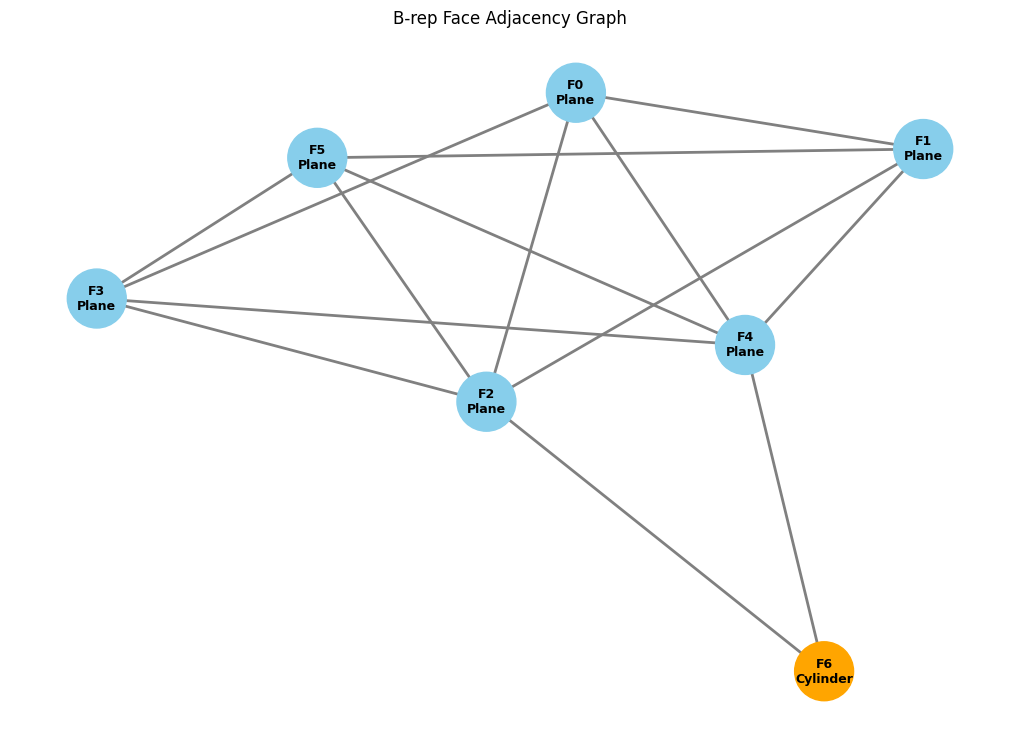

In [44]:

import networkx as nx
import matplotlib.pyplot as plt

# Create an empty undirected graph
G = nx.Graph()

# --------------------------------
# STEP 1: Add face nodes
# --------------------------------

for face_id in range(data.num_nodes):

    # Identify the surface type using node features
    if data.x[face_id, 1].item() == 1:
        surface_type = "Cylinder"
    else:
        surface_type = "Plane"

    G.add_node(
        face_id,
        surface_type=surface_type
    )


# --------------------------------
# STEP 2: Add connections
# --------------------------------

for i in range(data.edge_index.shape[1]):

    source = data.edge_index[0, i].item()
    target = data.edge_index[1, i].item()

    # Get edge attributes
    attributes = data.edge_attr[i]

    normalized_length = attributes[0].item()

    # Add only one copy of each undirected connection
    if not G.has_edge(source, target):

        G.add_edge(
            source,
            target,
            length=normalized_length
        )


# --------------------------------
# STEP 3: Prepare labels and colours
# --------------------------------

node_labels = {}

node_colors = []

for node in G.nodes:

    surface = G.nodes[node]["surface_type"]

    node_labels[node] = f"F{node}\n{surface}"

    if surface == "Cylinder":
        node_colors.append("orange")
    else:
        node_colors.append("skyblue")


# --------------------------------
# STEP 4: Draw the graph
# --------------------------------

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))

nx.draw(
    G,
    pos,
    with_labels=True,
    labels=node_labels,
    node_color=node_colors,
    node_size=1800,
    font_size=9,
    font_weight="bold",
    edge_color="gray",
    width=2
)

plt.title("B-rep Face Adjacency Graph")
plt.show()


In [45]:

import torch
from torch_geometric.nn import GCNConv

# Make results reproducible
torch.manual_seed(42)

# Create one GCN layer
# Input: 10 features per face
# Output: 16 learned features per face
gcn_layer = GCNConv(
    in_channels=10,
    out_channels=16
)

# Perform one forward pass
new_features = gcn_layer(
    data.x,
    data.edge_index
)

print("Original node features:", data.x.shape)
print("Updated node features:", new_features.shape)

print("\nUpdated representation of face 6:")
print(new_features[6])


/usr/local/lib/python3.13/site-packages/torch_geometric/inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
  return typing._eval_type(value, _globals, None)  # type: ignore


Original node features: torch.Size([7, 10])
Updated node features: torch.Size([7, 16])

Updated representation of face 6:
tensor([  6.9259,   5.2948,  -2.5000,   1.6998,  -8.2351,  -0.4341,  -3.1970,
        -12.4572,   1.7973,  -1.8172,  -2.8730,   3.1242,  10.4998,  -3.7546,
         -0.0670,   7.3559], grad_fn=<SelectBackward0>)
